# 03 · Evaluation Benchmark — Base Qwen3-4B vs Fine-Tuned PII Masker

Compares the **un-tuned base model** and the **QLoRA fine-tuned model** on **200 held-out test tickets** that neither model saw during training. Both get the identical system prompt, greedy decoding, and the same 4-bit weights.

| Metric | What it answers |
|---|---|
| **Strict JSON rate** | Is the raw output *exactly* a JSON object (no fences, no chatter)? |
| **Schema adherence** | After lenient extraction, does it pass the strict Pydantic contract? |
| **Text fidelity** | Is `masked_text` the source text with only tags swapped in (no rephrasing)? |
| **PII precision / recall / F1** | Typed, exact entity match (`[EMAIL]` must cover exactly the e-mail). |
| **Redaction recall** | Business metric: share of gold PII values that do **not** leak into the output. |
| **Category / urgency accuracy** | Routing quality, plus macro-F1 and a confusion matrix. |
| **Latency & tokens/sec** | Single-request speed on the T4. |

Runtime: **T4 GPU**, about 35–50 minutes. Needs the `HF_TOKEN` secret (read scope is enough; write scope uploads the results).

## 0. Install & imports

In [5]:
%pip install -q unsloth
%pip install -q "matplotlib>=3.8" "scikit-learn>=1.4"

In [6]:
import unsloth  # must come first so its patches apply
from unsloth import FastLanguageModel

import gc
import json
import os
import re
import time
from collections import Counter
from pathlib import Path
from typing import Dict, List, Literal, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from huggingface_hub import HfApi, hf_hub_download, login, whoami
from pydantic import BaseModel, ConfigDict, ValidationError, field_validator, model_validator
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

transformers.logging.set_verbosity_error()   # silences the harmless max_length / max_new_tokens notices
assert torch.cuda.is_available(), "No GPU — Runtime → Change runtime type → T4 GPU."
print(torch.cuda.get_device_name(0))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1117 06:18:21.019000 722 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1117 06:18:21.182000 722 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Tesla T4


## 1. Configuration

In [7]:
SEED = 42
N_EVAL = 200
BATCH_SIZE = 8              # batched greedy decoding for the quality metrics
N_SPEED = 20                # single-request runs for latency / tokens-per-second
MAX_SEQ_LENGTH = 2048
MAX_NEW_TOKENS_CAP = 1024

BASE_MODEL = "unsloth/Qwen3-4B-Instruct-2507-unsloth-bnb-4bit"
DATASET_NAME = "enterprise-pii-ticket-sft"
MODEL_SLUG = "pii-masker-qwen3-4b"
PUSH_RESULTS = True
OUT_DIR = Path("eval_results")
OUT_DIR.mkdir(exist_ok=True)


def get_secret(name: str) -> Optional[str]:
    try:
        from google.colab import userdata  # type: ignore
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    return os.environ.get(name)


HF_TOKEN = get_secret("HF_TOKEN")
if not HF_TOKEN:
    raise RuntimeError("HF_TOKEN missing: Colab 🔑 Secrets → add HF_TOKEN.")
login(token=HF_TOKEN, add_to_git_credential=False)
HF_USERNAME = whoami(token=HF_TOKEN)["name"]
HF_DATASET_REPO = f"{HF_USERNAME}/{DATASET_NAME}"
LORA_REPO = f"{HF_USERNAME}/{MODEL_SLUG}-lora"
print(f"Dataset: {HF_DATASET_REPO}\nFine-tuned: {LORA_REPO}\nBase: {BASE_MODEL}")

Dataset: Zain9989/enterprise-pii-ticket-sft
Fine-tuned: Zain9989/pii-masker-qwen3-4b-lora
Base: unsloth/Qwen3-4B-Instruct-2507-unsloth-bnb-4bit


## 2. Test set and output contract

In [8]:
test_full = load_dataset(HF_DATASET_REPO, split="test", token=HF_TOKEN).to_pandas()
eval_df, _ = train_test_split(test_full, train_size=N_EVAL, stratify=test_full["ticket_category"], random_state=SEED)
eval_df = eval_df.reset_index(drop=True)
print(f"Eval set: {len(eval_df)} tickets")
print(eval_df["ticket_category"].value_counts().to_string())
print(eval_df["origin"].value_counts().to_string())

PROMPT_CONFIG = json.loads(Path(hf_hub_download(
    HF_DATASET_REPO, "prompt_config.json", repo_type="dataset", token=HF_TOKEN)).read_text())
SYSTEM_PROMPT = PROMPT_CONFIG["system_prompt"]
USER_TEMPLATE = PROMPT_CONFIG["user_template"]
PII_TAGS: List[str] = PROMPT_CONFIG["pii_tags"]
CATEGORIES: List[str] = PROMPT_CONFIG["categories"]
URGENCY_LEVELS: List[str] = PROMPT_CONFIG["urgency_levels"]

TAG_PATTERN = re.compile(r"\[(" + "|".join(PII_TAGS) + r")\]")
TAG_SPLIT = re.compile(r"(\[(?:" + "|".join(PII_TAGS) + r")\])")


class TicketAnalysis(BaseModel):
    model_config = ConfigDict(extra="forbid", strict=True)
    masked_text: str
    detected_pii_types: List[Literal["PERSON", "EMAIL", "PHONE", "SSN", "CREDIT_CARD", "IP_ADDRESS", "API_KEY"]]
    ticket_category: Literal["Billing_and_Payments", "Technical_Support", "Security_and_Access",
                             "Legal_and_Compliance", "General_Inquiry"]
    urgency_level: Literal["Low", "Medium", "High"]

    @field_validator("detected_pii_types")
    @classmethod
    def _unique(cls, v):
        if len(set(v)) != len(v):
            raise ValueError("duplicate PII types")
        return v

    @model_validator(mode="after")
    def _consistent(self):
        if set(TAG_PATTERN.findall(self.masked_text)) != set(self.detected_pii_types):
            raise ValueError("tags in masked_text do not match detected_pii_types")
        return self


assert list(TicketAnalysis.model_fields["ticket_category"].annotation.__args__) == CATEGORIES
assert list(TicketAnalysis.model_fields["urgency_level"].annotation.__args__) == URGENCY_LEVELS

README.md:   0%|          | 0.00/3.05k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.23MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  559kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  565kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/300 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/300 [00:00<?, ? examples/s]

Eval set: 200 tickets
ticket_category
Billing_and_Payments    51
General_Inquiry         50
Legal_and_Compliance    37
Security_and_Access     37
Technical_Support       25
origin
ai4privacy    161
synthetic      39


prompt_config.json:   0%|          | 0.00/1.49k [00:00<?, ?B/s]

## 3. Parsing and scoring functions
PII is scored by **aligning** each `masked_text` back onto the source ticket: every tag becomes a capture group, so we recover exactly which characters the model redacted and under which tag. Gold labels go through the same alignment, so both sides are scored identically.

In [9]:
def extract_json(text: str) -> Optional[dict]:
    """Lenient: strip code fences / chatter and parse the first balanced JSON object."""
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    start = text.find("{")
    if start == -1:
        return None
    depth, in_str, esc = 0, False, False
    for i, ch in enumerate(text[start:], start):
        if in_str:
            if esc:
                esc = False
            elif ch == "\\":
                esc = True
            elif ch == '"':
                in_str = False
            continue
        if ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                try:
                    obj = json.loads(text[start:i + 1])
                    return obj if isinstance(obj, dict) else None
                except json.JSONDecodeError:
                    return None
    return None


def is_strict_json(text: str) -> bool:
    try:
        return isinstance(json.loads(text.strip()), dict)
    except json.JSONDecodeError:
        return False


def align_entities(source: str, masked: str) -> Optional[List[Tuple[str, str]]]:
    """Map masked_text back onto source. Returns [(TAG, original_value), ...] or None if the text was altered."""
    source, masked = source.strip(), masked.strip()
    parts = [p for p in TAG_SPLIT.split(masked) if p]
    tags = [p[1:-1] for p in parts if TAG_PATTERN.fullmatch(p)]
    if not tags:
        return [] if masked == source else None
    if len(tags) > 40:
        return None
    pattern = "".join("(.+?)" if TAG_PATTERN.fullmatch(p) else re.escape(p) for p in parts)
    m = re.fullmatch(pattern, source, flags=re.DOTALL)
    if m is None:
        return None
    return [(tag, value.strip()) for tag, value in zip(tags, m.groups())]


def score_prediction(row: pd.Series, raw: str) -> dict:
    gold_entities = align_entities(row["source_text"], row["masked_text"])
    assert gold_entities is not None, "gold masked_text must align with its source"

    parsed = extract_json(raw)
    pred: Optional[TicketAnalysis] = None
    schema_error = None
    if parsed is not None:
        try:
            pred = TicketAnalysis.model_validate(parsed)
        except ValidationError as e:
            schema_error = e.errors()[0]["msg"][:120]

    pred_entities = align_entities(row["source_text"], pred.masked_text) if pred else None
    gold_c = Counter(gold_entities)
    if pred_entities is None:
        # Unparseable, schema-invalid or rephrased: nothing can be credited.
        n_pred_tags = len(TAG_PATTERN.findall(pred.masked_text)) if pred else 0
        tp, fp, fn = 0, n_pred_tags, sum(gold_c.values())
        tp_by_type: Counter = Counter()
    else:
        pred_c = Counter(pred_entities)
        inter = gold_c & pred_c
        tp, fp, fn = sum(inter.values()), sum((pred_c - inter).values()), sum((gold_c - inter).values())
        tp_by_type = Counter()
        for (t, _), n in inter.items():
            tp_by_type[t] += n

    gold_values = [v for _, v in gold_entities if len(v) >= 3]
    if pred is None:
        redacted = 0                                        # an unusable answer protects nothing
    else:
        redacted = sum(v not in pred.masked_text for v in gold_values)

    return {
        "raw_output": raw,
        "strict_json": is_strict_json(raw),
        "parsed_json": parsed is not None,
        "schema_valid": pred is not None,
        "schema_error": schema_error,
        "text_faithful": pred_entities is not None,
        "pii_tp": tp, "pii_fp": fp, "pii_fn": fn,
        "gold_by_type": dict(Counter(t for t, _ in gold_entities)),
        "tp_by_type": dict(tp_by_type),
        "gold_values": len(gold_values), "values_redacted": redacted,
        "pred_category": pred.ticket_category if pred else None,
        "pred_urgency": pred.urgency_level if pred else None,
        "category_correct": bool(pred and pred.ticket_category == row["ticket_category"]),
        "urgency_correct": bool(pred and pred.urgency_level == row["urgency_level"]),
    }


# Unit checks for the scorer
_src = "Hi, I am John Smith, mail john@x.com today."
assert align_entities(_src, "Hi, I am [PERSON], mail [EMAIL] today.") == [("PERSON", "John Smith"), ("EMAIL", "john@x.com")]
assert align_entities(_src, "Hello, I am [PERSON], mail [EMAIL] today.") is None
assert align_entities(_src, _src) == []
assert extract_json('```json\n{"a": "b\\"}"}\n```') == {"a": 'b"}'}
print("✅ Scorer unit checks pass")

✅ Scorer unit checks pass


## 4. Generation helpers
Quality metrics use **batched** greedy decoding (left padding) for throughput. Speed is measured separately on **single requests**, because that's what a user of the API experiences.

In [10]:
def build_messages(ticket: str) -> List[dict]:
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": USER_TEMPLATE.format(ticket=ticket)}]


def stop_token_ids(tokenizer) -> List[int]:
    ids = {tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|im_end|>"),
           tokenizer.convert_tokens_to_ids("<|endoftext|>")}
    return sorted(i for i in ids if isinstance(i, int) and i >= 0)


def n_generated(ids: List[int], stops: List[int]) -> int:
    for k, t in enumerate(ids):
        if t in stops:
            return k + 1
    return len(ids)


@torch.inference_mode()
def generate(model, tokenizer, tickets: List[str]) -> Tuple[List[str], List[int]]:
    prompts = [tokenizer.apply_chat_template(build_messages(t), tokenize=False, add_generation_prompt=True)
               for t in tickets]
    enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
    in_len = enc["input_ids"].shape[1]
    longest_ticket = max(len(tokenizer(t, add_special_tokens=False)["input_ids"]) for t in tickets)
    stops = stop_token_ids(tokenizer)
    out = model.generate(
        **enc,
        max_new_tokens=min(MAX_NEW_TOKENS_CAP, longest_ticket + 192),
        do_sample=False, temperature=None, top_p=None, top_k=None,
        eos_token_id=stops, pad_token_id=tokenizer.pad_token_id,
    )
    gen = out[:, in_len:].tolist()
    return ([tokenizer.decode(g, skip_special_tokens=True) for g in gen],
            [n_generated(g, stops) for g in gen])


def run_quality_eval(model, tokenizer, label: str) -> pd.DataFrame:
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = "<|endoftext|>"
    rows = []
    t0 = time.time()
    for start in range(0, len(eval_df), BATCH_SIZE):
        batch = eval_df.iloc[start:start + BATCH_SIZE]
        outputs, _ = generate(model, tokenizer, batch["source_text"].tolist())
        for (_, row), raw in zip(batch.iterrows(), outputs):
            rows.append({"model": label, "origin": row["origin"], "gold_category": row["ticket_category"],
                         "gold_urgency": row["urgency_level"], **score_prediction(row, raw)})
        done = min(start + BATCH_SIZE, len(eval_df))
        print(f"\r{label}: {done}/{len(eval_df)}  ({time.time() - t0:.0f}s)", end="")
    print()
    return pd.DataFrame(rows)


@torch.inference_mode()
def run_speed_benchmark(model, tokenizer, label: str) -> dict:
    tokenizer.padding_side = "left"
    tickets = eval_df["source_text"].tolist()[:N_SPEED]
    generate(model, tokenizer, tickets[:1])                 # warm-up (kernel compilation, caches)
    latencies, tps, out_tokens = [], [], []
    for t in tickets:
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, n = generate(model, tokenizer, [t])
        torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        latencies.append(dt)
        tps.append(n[0] / dt)
        out_tokens.append(n[0])
    return {
        "model": label,
        "latency_p50_s": round(float(np.median(latencies)), 2),
        "latency_p95_s": round(float(np.percentile(latencies, 95)), 2),
        "tokens_per_sec_mean": round(float(np.mean(tps)), 1),
        "output_tokens_mean": round(float(np.mean(out_tokens)), 1),
        "peak_vram_gb": round(torch.cuda.max_memory_reserved() / 1024**3, 2),
    }


def free_model():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

## 5. Base model (no fine-tuning)
The base model uses **its own** chat template, which is how it would be served out of the box. It gets the same detailed system prompt with the full schema, so this is a fair zero-shot baseline, not a straw man.

In [11]:
base_model, base_tok = FastLanguageModel.from_pretrained(
    BASE_MODEL, max_seq_length=MAX_SEQ_LENGTH, dtype=None, load_in_4bit=True, token=HF_TOKEN)
FastLanguageModel.for_inference(base_model)

base_results = run_quality_eval(base_model, base_tok, "Base Qwen3-4B")
base_speed = run_speed_benchmark(base_model, base_tok, "Base Qwen3-4B")
print(base_speed)
print("\nSample base output:\n", base_results.iloc[0]["raw_output"][:600])

del base_model, base_tok
free_model()

==((====))==  Unsloth 2026.11.5: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Base Qwen3-4B: 200/200  (321s)
{'model': 'Base Qwen3-4B', 'latency_p50_s': 2.96, 'latency_p95_s': 3.89, 'tokens_per_sec_mean': 28.8, 'output_tokens_mean': 87.2, 'peak_vram_gb': 4.37}

Sample base output:
 {
  "masked_text": "A legal webinar is scheduled by [PERSON], [PERSON], and [PERSON]. Our esteemed speaker Dr. Cameron from Trentino-Alto Adige/Südtirol will lead the session. Registration is open on https://knowing-credential.name.",
  "detected_pii_types": [
    "PERSON"
  ],
  "ticket_category": "Legal_and_Compliance",
  "urgency_level": "Low"
}


## 6. Fine-tuned model (base + QLoRA adapter)
Loading the adapter repo pulls the base weights plus the adapter, and the plain ChatML template saved with it.

In [12]:
ft_model, ft_tok = FastLanguageModel.from_pretrained(
    LORA_REPO, max_seq_length=MAX_SEQ_LENGTH, dtype=None, load_in_4bit=True, token=HF_TOKEN)
FastLanguageModel.for_inference(ft_model)
_probe = ft_tok.apply_chat_template(build_messages("test"), tokenize=False, add_generation_prompt=True)
assert "<think>" not in _probe and _probe.endswith("<|im_start|>assistant\n"), "unexpected chat template"

ft_results = run_quality_eval(ft_model, ft_tok, "Fine-tuned (QLoRA)")
ft_speed = run_speed_benchmark(ft_model, ft_tok, "Fine-tuned (QLoRA)")
print(ft_speed)
print("\nSample fine-tuned output:\n", ft_results.iloc[0]["raw_output"][:600])

==((====))==  Unsloth 2026.11.5: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Fine-tuned (QLoRA): 200/200  (258s)
{'model': 'Fine-tuned (QLoRA)', 'latency_p50_s': 2.76, 'latency_p95_s': 3.76, 'tokens_per_sec_mean': 26.3, 'output_tokens_mean': 73.8, 'peak_vram_gb': 4.61}

Sample fine-tuned output:
 {"masked_text": "A legal webinar is scheduled by Prohaska, Bernier and Powlowski. Our esteemed speaker Dr. [PERSON] from Trentino-Alto Adige/Südtirol will lead the session. Registration is open on https://knowing-credential.name.", "detected_pii_types": ["PERSON"], "ticket_category": "Security_and_Access", "urgency_level": "Low"}


## 7. Results

In [13]:
def summarize(df: pd.DataFrame) -> dict:
    tp, fp, fn = df["pii_tp"].sum(), df["pii_fp"].sum(), df["pii_fn"].sum()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    cat_pred = df["pred_category"].fillna("INVALID")
    return {
        "strict_json_rate": df["strict_json"].mean(),
        "schema_adherence": df["schema_valid"].mean(),
        "text_fidelity": df["text_faithful"].mean(),
        "pii_precision": precision,
        "pii_recall": recall,
        "pii_f1": f1,
        "redaction_recall": df["values_redacted"].sum() / max(df["gold_values"].sum(), 1),
        "category_accuracy": df["category_correct"].mean(),
        "category_macro_f1": f1_score(df["gold_category"], cat_pred, labels=CATEGORIES, average="macro", zero_division=0),
        "urgency_accuracy": df["urgency_correct"].mean(),
    }


summary = pd.DataFrame({
    "Base Qwen3-4B": summarize(base_results),
    "Fine-tuned (QLoRA)": summarize(ft_results),
})
summary["Δ (pp)"] = (summary["Fine-tuned (QLoRA)"] - summary["Base Qwen3-4B"]) * 100
speed = pd.DataFrame([base_speed, ft_speed]).set_index("model")

pd.options.display.float_format = "{:.3f}".format
print(summary.to_string())
print()
print(speed.to_string())

                   Base Qwen3-4B  Fine-tuned (QLoRA)  Δ (pp)
strict_json_rate           1.000               1.000   0.000
schema_adherence           0.615               1.000  38.500
text_fidelity              0.540               0.990  45.000
pii_precision              0.607               0.979  37.132
pii_recall                 0.287               0.965  67.832
pii_f1                     0.390               0.972  58.228
redaction_recall           0.384               0.989  60.563
category_accuracy          0.505               0.980  47.500
category_macro_f1          0.602               0.978  37.549
urgency_accuracy           0.375               0.980  60.500

                    latency_p50_s  latency_p95_s  tokens_per_sec_mean  output_tokens_mean  peak_vram_gb
model                                                                                                  
Base Qwen3-4B               2.960          3.890               28.800              87.200         4.370
Fine-tuned (QLoR

### Per-type PII recall and accuracy by label provenance
`synthetic` rows carry gold routing labels; `ai4privacy` rows carry weak (lexicon) labels, so their accuracy measures agreement with the labeler.

In [14]:
def per_type_recall(df: pd.DataFrame) -> Dict[str, float]:
    gold, tp = Counter(), Counter()
    for g, t in zip(df["gold_by_type"], df["tp_by_type"]):
        gold.update(g)
        tp.update(t)
    return {tag: (tp[tag] / gold[tag] if gold[tag] else float("nan")) for tag in PII_TAGS}


per_type = pd.DataFrame({
    "Base Qwen3-4B": per_type_recall(base_results),
    "Fine-tuned (QLoRA)": per_type_recall(ft_results),
})
per_type["gold count"] = [sum(g.get(t, 0) for g in ft_results["gold_by_type"]) for t in PII_TAGS]
print("Typed PII recall by entity type:\n", per_type.to_string(), "\n")

by_origin = (pd.concat([base_results, ft_results])
             .groupby(["model", "origin"])[["schema_valid", "category_correct", "urgency_correct"]]
             .mean())
print("By label provenance:\n", by_origin.to_string(), "\n")

errors = ft_results[~ft_results["schema_valid"] | ~ft_results["text_faithful"] | (ft_results["pii_fn"] > 0)]
print(f"Fine-tuned model: {len(errors)} tickets with a schema, fidelity or missed-PII error")
for _, r in errors.head(5).iterrows():
    print("—" * 80)
    print(f"schema_valid={r.schema_valid} faithful={r.text_faithful} missed={r.pii_fn} extra={r.pii_fp} "
          f"err={r.schema_error}")
    print(r.raw_output[:400])

Typed PII recall by entity type:
              Base Qwen3-4B  Fine-tuned (QLoRA)  gold count
PERSON               0.250               0.940         116
EMAIL                0.571               1.000          42
PHONE                0.182               0.955          22
SSN                  0.333               1.000          15
CREDIT_CARD          0.346               1.000          26
IP_ADDRESS           0.169               0.983          59
API_KEY              0.167               0.833           6 

By label provenance:
                                schema_valid  category_correct  urgency_correct
model              origin                                                     
Base Qwen3-4B      ai4privacy         0.602             0.472            0.342
                   synthetic          0.667             0.641            0.513
Fine-tuned (QLoRA) ai4privacy         1.000             0.975            0.975
                   synthetic          1.000             1.000            1.

## 8. Charts

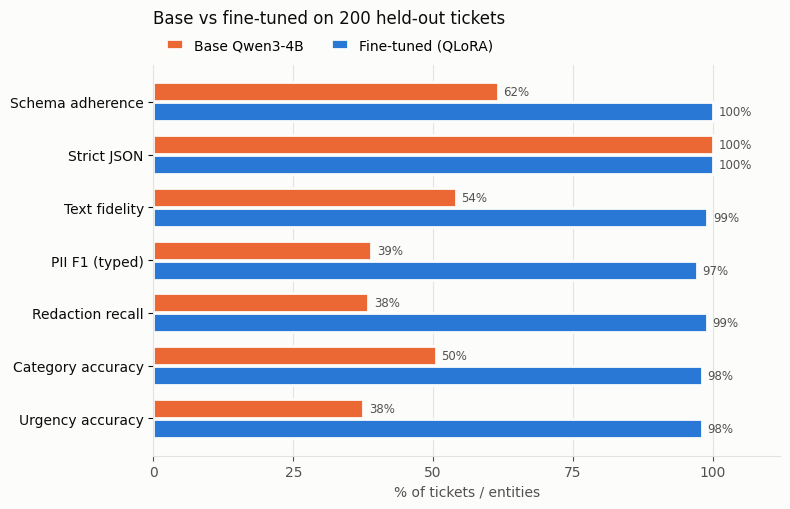

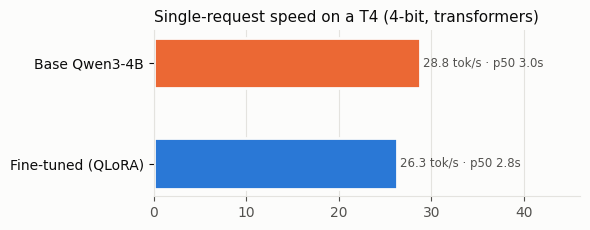

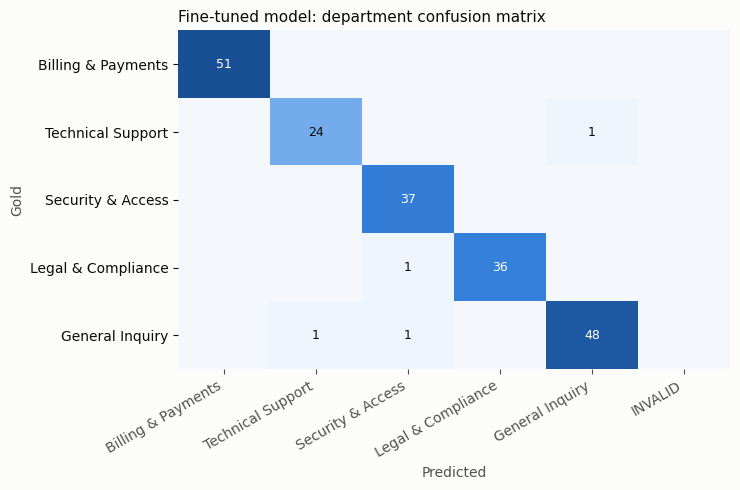

In [15]:
import matplotlib.pyplot as plt

FT_COLOR, BASE_COLOR = "#2a78d6", "#eb6834"          # validated categorical slots 1 & 2
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

metric_labels = {
    "schema_adherence": "Schema adherence", "strict_json_rate": "Strict JSON",
    "text_fidelity": "Text fidelity", "pii_f1": "PII F1 (typed)", "redaction_recall": "Redaction recall",
    "category_accuracy": "Category accuracy", "urgency_accuracy": "Urgency accuracy",
}
keys = list(metric_labels)
y = np.arange(len(keys))
h = 0.36
fig, ax = plt.subplots(figsize=(8, 5.2))
for offset, col, color in [(-h / 2 - 0.01, "Base Qwen3-4B", BASE_COLOR), (h / 2 + 0.01, "Fine-tuned (QLoRA)", FT_COLOR)]:
    vals = summary.loc[keys, col].values * 100
    ax.barh(y + offset, vals, height=h, color=color, label=col, edgecolor=SURFACE, linewidth=2)
    for yi, v in zip(y + offset, vals):
        ax.text(v + 1, yi, f"{v:.0f}%", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(y, [metric_labels[k] for k in keys])
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title(f"Base vs fine-tuned on {N_EVAL} held-out tickets", loc="left", color=INK, fontsize=12, pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, handlelength=1.2)
ax.set_xlabel("% of tickets / entities")
fig.tight_layout()
fig.savefig(OUT_DIR / "benchmark_quality.png", dpi=160)
plt.show()

# Throughput gets its own chart: different unit, never a second axis.
fig, ax = plt.subplots(figsize=(6, 2.4))
labels = ["Base Qwen3-4B", "Fine-tuned (QLoRA)"]
vals = [speed.loc[m, "tokens_per_sec_mean"] for m in labels]
ax.barh(labels, vals, color=[BASE_COLOR, FT_COLOR], height=0.5, edgecolor=SURFACE, linewidth=2)
for i, (m, v) in enumerate(zip(labels, vals)):
    ax.text(v * 1.01, i, f"{v:.1f} tok/s · p50 {speed.loc[m, 'latency_p50_s']:.1f}s", va="center", fontsize=8.5, color=INK_2)
ax.invert_yaxis()
ax.set_xlim(0, max(vals) * 1.6)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Single-request speed on a T4 (4-bit, transformers)", loc="left", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "benchmark_speed.png", dpi=160)
plt.show()

# Confusion matrix: sequential single-hue ramp.
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#9ec5f4", "#3987e5", "#184f95"])
labels_cm = CATEGORIES + ["INVALID"]
cm = confusion_matrix(ft_results["gold_category"], ft_results["pred_category"].fillna("INVALID"), labels=labels_cm)
cm = cm[: len(CATEGORIES)]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.imshow(cm, cmap=blues, aspect="auto")
short = [c.replace("_and_", " & ").replace("_", " ") for c in labels_cm]
ax.set_xticks(range(len(labels_cm)), short, rotation=30, ha="right")
ax.set_yticks(range(len(CATEGORIES)), short[: len(CATEGORIES)])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="#ffffff" if cm[i, j] > cm.max() * 0.55 else INK)
ax.set_xlabel("Predicted")
ax.set_ylabel("Gold")
ax.set_title("Fine-tuned model: department confusion matrix", loc="left", color=INK, fontsize=11)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrix.png", dpi=160)
plt.show()

## 9. Save, print README table, and publish

In [16]:
def pct(x: float) -> str:
    return f"{x * 100:.1f}%"


rows_md = [
    ("Strict JSON (raw output is pure JSON)", "strict_json_rate"),
    ("Schema adherence (Pydantic)", "schema_adherence"),
    ("Text fidelity (no rephrasing)", "text_fidelity"),
    ("PII precision (typed, exact)", "pii_precision"),
    ("PII recall (typed, exact)", "pii_recall"),
    ("PII F1 (typed, exact)", "pii_f1"),
    ("Redaction recall (no PII leaked)", "redaction_recall"),
    ("Category accuracy", "category_accuracy"),
    ("Category macro-F1", "category_macro_f1"),
    ("Urgency accuracy", "urgency_accuracy"),
]
md = ["| Metric | Base Qwen3-4B | Fine-tuned (QLoRA) |", "|---|---:|---:|"]
for name, key in rows_md:
    md.append(f"| {name} | {pct(summary.loc[key, 'Base Qwen3-4B'])} | **{pct(summary.loc[key, 'Fine-tuned (QLoRA)'])}** |")
md.append(f"| Tokens/sec (single request, T4) | {base_speed['tokens_per_sec_mean']} | {ft_speed['tokens_per_sec_mean']} |")
md.append(f"| Latency p50 / p95 (s) | {base_speed['latency_p50_s']} / {base_speed['latency_p95_s']} | "
          f"{ft_speed['latency_p50_s']} / {ft_speed['latency_p95_s']} |")
README_TABLE = "\n".join(md)
print(README_TABLE)

results = {
    "n_eval": N_EVAL,
    "eval_set": f"{HF_DATASET_REPO} (test split, stratified sample, seed {SEED})",
    "base_model": BASE_MODEL,
    "fine_tuned_model": LORA_REPO,
    "decoding": "greedy, identical system prompt",
    "quality": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in summary.drop(columns="Δ (pp)").to_dict().items()},
    "speed": {base_speed["model"]: base_speed, ft_speed["model"]: ft_speed},
    "per_type_recall": {k: {t: (None if np.isnan(v) else round(float(v), 4)) for t, v in d.items()}
                        for k, d in per_type.drop(columns="gold count").to_dict().items()},
    "gpu": torch.cuda.get_device_name(0),
}
(OUT_DIR / "eval_results.json").write_text(json.dumps(results, indent=2))
(OUT_DIR / "README_table.md").write_text(README_TABLE + "\n")
pd.concat([base_results, ft_results]).drop(columns=["gold_by_type", "tp_by_type"]).to_parquet(
    OUT_DIR / "predictions.parquet", index=False)

if PUSH_RESULTS:
    try:
        HfApi(token=HF_TOKEN).upload_folder(folder_path=str(OUT_DIR), path_in_repo="eval", repo_id=LORA_REPO,
                                            commit_message=f"Add {N_EVAL}-ticket benchmark results")
        print(f"✅ Results at https://huggingface.co/{LORA_REPO}/tree/main/eval")
    except Exception as e:
        print(f"⚠️  Upload skipped ({type(e).__name__}: {e}). Results are saved locally in {OUT_DIR}/")

for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.name:24} {p.stat().st_size / 1024:8.1f} KB")

| Metric | Base Qwen3-4B | Fine-tuned (QLoRA) |
|---|---:|---:|
| Strict JSON (raw output is pure JSON) | 100.0% | **100.0%** |
| Schema adherence (Pydantic) | 61.5% | **100.0%** |
| Text fidelity (no rephrasing) | 54.0% | **99.0%** |
| PII precision (typed, exact) | 60.7% | **97.9%** |
| PII recall (typed, exact) | 28.7% | **96.5%** |
| PII F1 (typed, exact) | 39.0% | **97.2%** |
| Redaction recall (no PII leaked) | 38.4% | **98.9%** |
| Category accuracy | 50.5% | **98.0%** |
| Category macro-F1 | 60.2% | **97.8%** |
| Urgency accuracy | 37.5% | **98.0%** |
| Tokens/sec (single request, T4) | 28.8 | 26.3 |
| Latency p50 / p95 (s) | 2.96 / 3.89 | 2.76 / 3.76 |
✅ Results at https://huggingface.co/Zain9989/pii-masker-qwen3-4b-lora/tree/main/eval
README_table.md               0.7 KB
benchmark_quality.png        77.6 KB
benchmark_speed.png          31.5 KB
confusion_matrix.png         87.3 KB
eval_results.json             1.8 KB
predictions.parquet          62.8 KB
